In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import pandas as pd
import numpy as np
import sqlite3


df = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head(10)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
conn = sqlite3.connect('churn.db')   
df.to_sql('raw_customers', conn, if_exists='replace', index=False)

pd.read_sql("SELECT COUNT(*) AS count FROM raw_customers", conn)  

,count
0,7043


In [5]:
conn.executescript("""
DROP TABLE IF EXISTS customers;
CREATE TABLE customers AS
SELECT customerID, gender, SeniorCitizen, Partner, Dependents, tenure, Churn
FROM raw_customers;
""")

In [6]:
conn.executescript("""
DROP TABLE IF EXISTS services;
create table services AS 
select customerID, PhoneService, MultipleLines, InternetService, OnlineSecurity, DeviceProtection,TechSupport,StreamingTV,StreamingMovies
from raw_customers;
""")

In [7]:
conn.executescript("""
drop table if exists billing;
create table billing as 
SELECT customerID, Contract, PaperlessBilling, PaymentMethod,
       MonthlyCharges, TotalCharges
FROM raw_customers;
""")

In [8]:
pd.read_sql("""
SELECT c.customerID, c.Churn, b.Contract, s.InternetService
FROM customers c
JOIN billing b ON c.customerID = b.customerID
JOIN services s ON c.customerID = s.customerID
LIMIT 5
""", conn)

,customerID,Churn,Contract,InternetService
0,7590-VHVEG,No,Month-to-month,DSL
1,5575-GNVDE,No,One year,DSL
2,3668-QPYBK,Yes,Month-to-month,DSL
3,7795-CFOCW,No,One year,DSL
4,9237-HQITU,Yes,Month-to-month,Fiber optic


In [9]:
pd.read_sql("""
SELECT s.InternetService,
       COUNT(*) AS customers,
       SUM(c.Churn = 'Yes') AS churned,
       ROUND(AVG(c.Churn = 'Yes') * 100, 1) AS churn_rate_pct
FROM customers c
JOIN services s ON c.customerID = s.customerID
GROUP BY s.InternetService
ORDER BY churn_rate_pct DESC
""", conn)

,InternetService,customers,churned,churn_rate_pct
0,Fiber optic,3096,1297,41.9
1,DSL,2421,459,19.0
2,No,1526,113,7.4


In [10]:
pd.read_sql("""
select count(*) as customers , b.PaymentMethod , sum(c.churn="Yes") as churned  , round(avg(c.churn="Yes")*100,1) as churn_rate
from customers c join billing b on c.customerID = b.customerID
group by b.PaymentMethod
""",conn)

,customers,PaymentMethod,churned,churn_rate
0,1544,Bank transfer (automatic),258,16.7
1,1522,Credit card (automatic),232,15.2
2,2365,Electronic check,1071,45.3
3,1612,Mailed check,308,19.1


In [11]:
pd.read_sql("""
select count(*) as customers , round(SUM(b.MonthlyCharges),2) as revenue_loss
from customers c join billing b on c.customerID = b.customerID
where c.churn="Yes"
""",conn)

,customers,revenue_loss
0,1869,139130.85


**Churned customers represent about 139K in lost monthly recurring revenue, roughly 1.67M per year, which sets the budget ceiling for any retention program.**

In [12]:
pd.read_sql("""
SELECT c.Churn,
       COUNT(*) AS customers,
       ROUND(AVG(b.MonthlyCharges), 2) AS avg_monthly_charge,
       ROUND(SUM(b.MonthlyCharges), 2) AS total_monthly_revenue
FROM customers c
JOIN billing b ON c.customerID = b.customerID
GROUP BY c.Churn
""", conn)

,Churn,customers,avg_monthly_charge,total_monthly_revenue
0,No,5174,61.27,316985.75
1,Yes,1869,74.44,139130.85


In [13]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [14]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

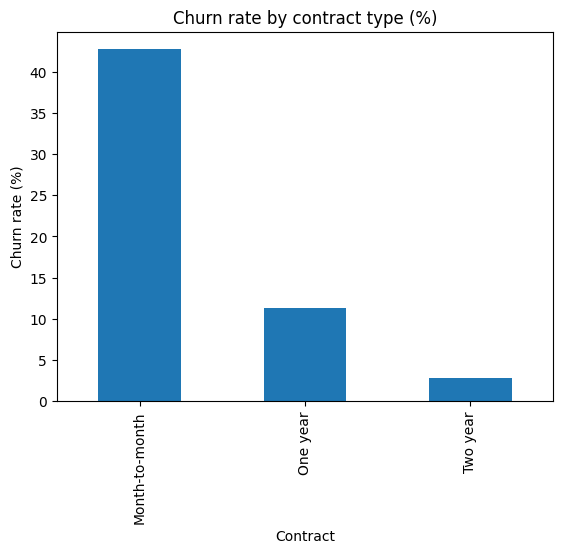

In [16]:
import matplotlib.pyplot as plt

churn_by_contract = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
churn_by_contract.plot(kind='bar', title='Churn rate by contract type (%)')
plt.ylabel('Churn rate (%)')
plt.show()

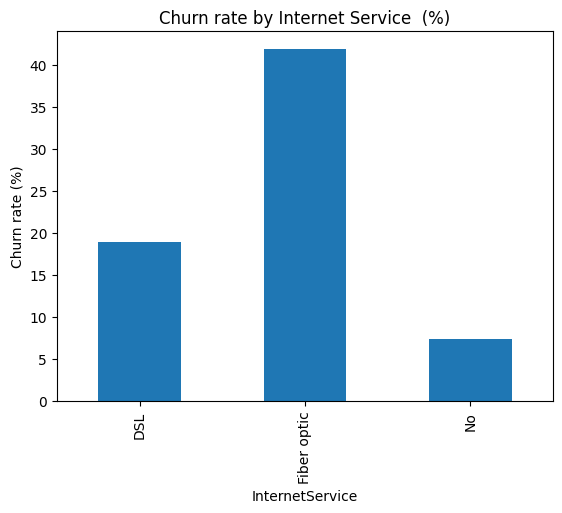

In [17]:
import matplotlib.pyplot as plt

churn_by_contract = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
churn_by_contract.plot(kind='bar', title='Churn rate by Internet Service  (%)')
plt.ylabel('Churn rate (%)')
plt.show()

In [18]:
y = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns=['customerID', 'Churn'])

In [19]:
X = pd.get_dummies(X, drop_first=True)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [20]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (4225, 30)
Validation: (1409, 30)
Testing: (1409, 30)


In [21]:
from sklearn.preprocessing import StandardScaler

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [22]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [23]:
from sklearn.metrics import accuracy_score

log_reg_train_pred = log_reg.predict(X_train)

log_reg_val_pred = log_reg.predict(X_val)

print("Logistic Regression")
print("Training Accuracy:", round(accuracy_score(y_train, log_reg_train_pred), 3))
print("Validation Accuracy:", round(accuracy_score(y_val, log_reg_val_pred), 3))

Logistic Regression
Training Accuracy: 0.805
Validation Accuracy: 0.802


In [24]:
from sklearn.metrics import classification_report

log_reg_proba = log_reg.predict_proba(X_val)[:, 1]
log_reg_pred = (log_reg_proba >= 0.5).astype(int)

print(classification_report(y_val, log_reg_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_proba = rf.predict_proba(X_val)[:, 1]

rf_pred = (rf_proba >= 0.5).astype(int)

print(classification_report(y_val, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.63      0.47      0.54       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409



In [26]:
rf_train_pred = rf.predict(X_train)
rf_val_pred = rf.predict(X_val)

print("Random Forest")
print("Training Accuracy:", round(accuracy_score(y_train, rf_train_pred), 3))
print("Validation Accuracy:", round(accuracy_score(y_val, rf_val_pred), 3))

Random Forest
Training Accuracy: 0.998
Validation Accuracy: 0.788


In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [5, 8, 12, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", round(grid_search.best_score_, 3))

Best Parameters: {'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV F1 Score: 0.572


In [28]:
best_rf = grid_search.best_estimator_

best_rf_train_pred = best_rf.predict(X_train)

best_rf_val_pred = best_rf.predict(X_val)

print("Tuned Random Forest")
print("Training Accuracy:",
      round(accuracy_score(y_train, best_rf_train_pred), 3))

print("Validation Accuracy:",
      round(accuracy_score(y_val, best_rf_val_pred), 3))

print("\nValidation Classification Report:")
print(classification_report(y_val, best_rf_val_pred))

Tuned Random Forest
Training Accuracy: 0.88
Validation Accuracy: 0.791

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.87      1035
           1       0.66      0.45      0.53       374

    accuracy                           0.79      1409
   macro avg       0.74      0.68      0.70      1409
weighted avg       0.78      0.79      0.78      1409



In [29]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

xgb_proba = xgb.predict_proba(X_val)[:, 1]

xgb_pred = (xgb_proba >= 0.5).astype(int)

print(classification_report(y_val, xgb_pred))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.65      0.47      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [30]:
xgb_train_pred = xgb.predict(X_train)
xgb_val_pred = xgb.predict(X_val)

print("XGBoost")
print("Training Accuracy:", round(accuracy_score(y_train, xgb_train_pred), 3))
print("Validation Accuracy:", round(accuracy_score(y_val, xgb_val_pred), 3))

XGBoost
Training Accuracy: 0.826
Validation Accuracy: 0.793


In [31]:
best_rf_proba = best_rf.predict_proba(X_val)[:, 1]

In [32]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    'Logistic Regression': log_reg_proba,
    'Random Forest (Original)': rf_proba,
    'Random Forest (Tuned)': best_rf_proba,
    'XGBoost': xgb_proba
}

results = []

for name, probabilities in models.items():

    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, probabilities)
    })

comparison_df = pd.DataFrame(results)

comparison_df.round(3).sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.793,0.652,0.471,0.547,0.839
1,Logistic Regression,0.802,0.657,0.532,0.588,0.836
2,Random Forest (Tuned),0.791,0.655,0.452,0.535,0.833
3,Random Forest (Original),0.788,0.634,0.473,0.542,0.817


In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

results = []

for t in thresholds:
    val_pred = (log_reg_proba >= t).astype(int)

    results.append({
        'Threshold': t,
        'Precision': precision_score(y_val, val_pred),
        'Recall': recall_score(y_val, val_pred),
        'F1 Score': f1_score(y_val, val_pred)
    })
print("Logistic Regression")
pd.DataFrame(results).round(3)

Logistic Regression


,Threshold,Precision,Recall,F1 Score
0,0.2,0.465,0.840,0.599
1,0.3,0.538,0.751,0.627
2,0.4,0.597,0.644,0.620
3,0.5,0.657,0.532,0.588
4,0.6,0.712,0.377,0.493


In [34]:
from sklearn.metrics import confusion_matrix
threshold = 0.3

test_proba = log_reg.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

print("Model: Logistic Regression")
print("Selected Threshold:", threshold)

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

print("\nROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

Model: Logistic Regression
Selected Threshold: 0.3

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409


ROC-AUC: 0.843

Confusion Matrix:
[[780 255]
 [ 91 283]]


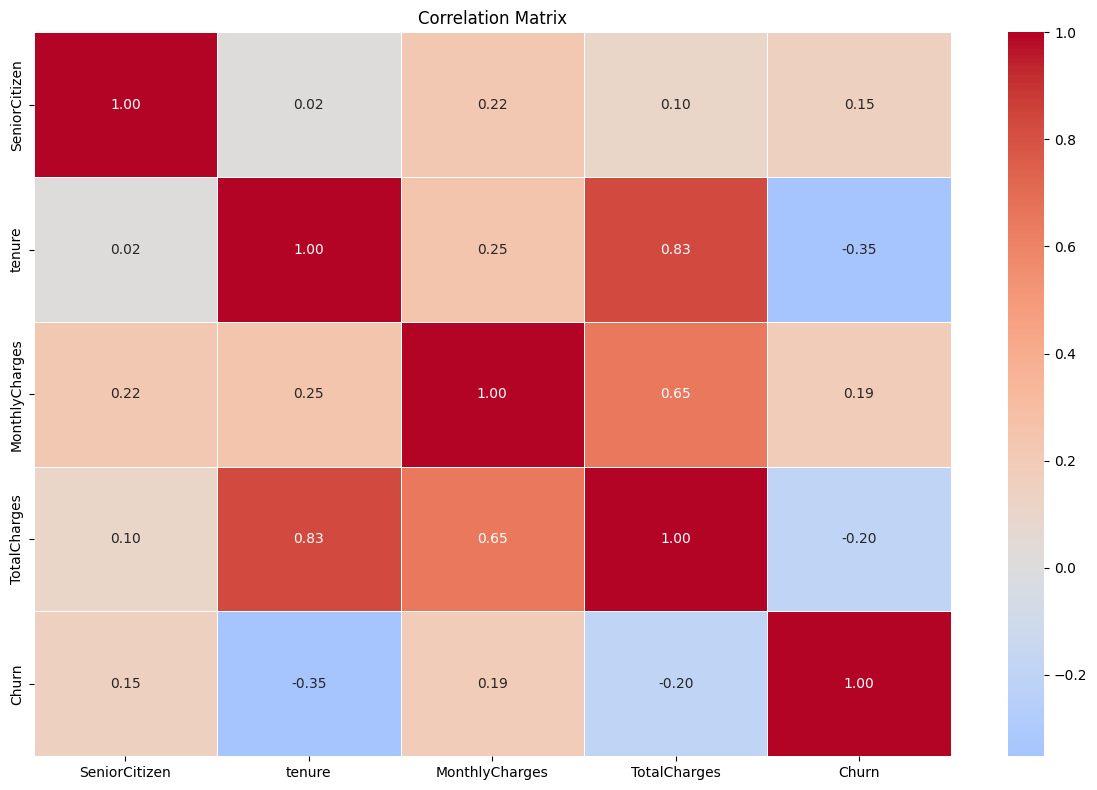

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_data = df.copy()

corr_data['Churn'] = corr_data['Churn'].map({
    'Yes': 1,
    'No': 0
})

corr_data = corr_data.select_dtypes(include='number')

cols = [col for col in corr_data.columns if col != 'Churn'] + ['Churn']
corr_data = corr_data[cols]

corr_matrix = corr_data.corr()


plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [36]:
train_df = df.loc[X_train.index]

avg_monthly_revenue = train_df.loc[
    train_df['Churn'] == 'Yes',
    'MonthlyCharges'
].mean()

customer_value = avg_monthly_revenue * 12

print(f"Average monthly revenue per churned customer: {avg_monthly_revenue:.2f}")
print(f"Estimated 12-month customer revenue: {customer_value:.2f}")

Average monthly revenue per churned customer: 74.54
Estimated 12-month customer revenue: 894.50


In [37]:
import pandas as pd


threshold = 0.3

test_proba = log_reg.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

flagged_customers = df.loc[X_test.index].copy()
flagged_customers['Predicted_Churn'] = test_pred

flagged_customers = flagged_customers[
    flagged_customers['Predicted_Churn'] == 1
]

flagged_customers['Estimated_Annual_Revenue'] = (
    flagged_customers['MonthlyCharges'] * 12
)

total_revenue_at_risk = flagged_customers[
    'Estimated_Annual_Revenue'
].sum()

business_results = pd.DataFrame({
    'Metric': [
        'Average Monthly Revenue (Churned Customers)',
        'Estimated Annual Revenue per Customer',
        'Number of Customers Flagged',
        'Estimated Annual Revenue at Risk'
    ],
    'Value': [
        round(avg_monthly_revenue, 2),
        round(avg_monthly_revenue * 12, 2),
        len(flagged_customers),
        round(total_revenue_at_risk, 2)
    ]
})

business_results

,Metric,Value
0,Average Monthly Revenue (Churned Customers),74.54
1,Estimated Annual Revenue per Customer,894.50
2,Number of Customers Flagged,538.00
3,Estimated Annual Revenue at Risk,495387.60


In [38]:
retention_rates = [0.10, 0.20, 0.30, 0.40, 0.50]

avg_annual_revenue = flagged_customers['Estimated_Annual_Revenue'].mean()

results = []

for rate in retention_rates:

    expected_retained = len(flagged_customers) * rate

    estimated_revenue_saved = (
        flagged_customers['Estimated_Annual_Revenue'].sum() * rate
    )

    results.append({
        'Retention Success Rate': f'{rate:.0%}',
        'Expected Retained Customers': round(expected_retained),
        'Estimated Revenue Retained': round(estimated_revenue_saved, 2)
    })

scenario_analysis = pd.DataFrame(results)

scenario_analysis

,Retention Success Rate,Expected Retained Customers,Estimated Revenue Retained
0,10%,54,49538.76
1,20%,108,99077.52
2,30%,161,148616.28
3,40%,215,198155.04
4,50%,269,247693.80
